### Featuretools Deep Feature Synthesis and AutoML for SafeDrive Insurance Ltd.

##### Load the cleaned data and define feature_cols without the target

In [1]:
import pandas as pd
import numpy as np
import featuretools as ft

df = pd.read_csv("Cleaned_df.csv")

feature_cols = [c for c in df.columns if c != "is_claim"]
assert "is_claim" not in feature_cols

In [2]:
df.head()

,policy_tenure,age_of_car,age_of_policyholder,population_density,turning_radius,height,gross_weight,ncap_rating,Power_to_Weight_Ratio,is_esc,...,segment_B2,segment_C1,fuel_type_Diesel,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 Turbocharged Revotorq,engine_type_K Series Dual jet,engine_type_i-DTEC,High_Risk_Driver_Flag,is_claim
0,0.515874,0.05,0.644231,4990.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
1,0.672619,0.02,0.375000,27003.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
2,0.841110,0.02,0.384615,4076.0,4.6,1475,1185,0,0.034059,0,...,0,0,0,0,0,0,0,0,0,0
3,0.900277,0.11,0.432692,21622.0,4.8,1515,1335,2,0.066292,1,...,0,1,0,0,1,0,0,0,0,0
4,0.596403,0.11,0.634615,34738.0,5.0,1490,1155,2,0.058061,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
feature_cols,len(feature_cols)

(['policy_tenure',
  'age_of_car',
  'age_of_policyholder',
  'population_density',
  'turning_radius',
  'height',
  'gross_weight',
  'ncap_rating',
  'Power_to_Weight_Ratio',
  'is_esc',
  'is_adjustable_steering',
  'is_tpms',
  'is_parking_sensors',
  'is_parking_camera',
  'is_brake_assist',
  'is_power_door_locks',
  'is_day_night_rear_view_mirror',
  'is_speed_alert',
  'airbags_1',
  'airbags_2',
  'area_cluster_C1',
  'area_cluster_C10',
  'area_cluster_C11',
  'area_cluster_C12',
  'area_cluster_C13',
  'area_cluster_C14',
  'area_cluster_C15',
  'area_cluster_C16',
  'area_cluster_C17',
  'area_cluster_C18',
  'area_cluster_C19',
  'area_cluster_C2',
  'area_cluster_C20',
  'area_cluster_C21',
  'area_cluster_C22',
  'area_cluster_C3',
  'area_cluster_C4',
  'area_cluster_C5',
  'area_cluster_C6',
  'area_cluster_C7',
  'area_cluster_C8',
  'area_cluster_C9',
  'segment_A',
  'segment_B1',
  'segment_B2',
  'segment_C1',
  'fuel_type_Diesel',
  'engine_type_1.2 L K Series E

##### Build the EntitySet

In [4]:
es = ft.EntitySet(id="insurance")
es.add_dataframe(
    dataframe_name="policies",
    dataframe=df[feature_cols],
    index="row_id",
    make_index=True      # creates a row id, so no real column is used as the index
)

Entityset: insurance
  DataFrames:
    policies [Rows: 58592, Columns: 54]
  Relationships:
    No relationships

In [5]:
# Create features using Deep Feature Synthesis (DFS)
feature_matrix, feature_defs = ft.dfs(
    entityset=es,
    target_dataframe_name="policies",
    trans_primitives=["multiply_numeric", "add_numeric"],
    agg_primitives=[],
    max_depth=1
)

In [6]:
# Compare the row counts and order of the original dataset with the cleaned dataset
assert "is_claim" not in feature_matrix.columns

original_cols = set(feature_cols)
new_features = [c for c in feature_matrix.columns if c not in original_cols]

print("Total DFS features:", feature_matrix.shape[1])
print("Original features :", len(original_cols))
print("New candidate features:", len(new_features))
print(new_features)     # the list of new candidate names

Total DFS features: 2809
Original features : 53
New candidate features: 2756
['High_Risk_Driver_Flag + Power_to_Weight_Ratio', 'High_Risk_Driver_Flag + is_adjustable_steering', 'High_Risk_Driver_Flag + is_brake_assist', 'High_Risk_Driver_Flag + is_day_night_rear_view_mirror', 'High_Risk_Driver_Flag + is_esc', 'High_Risk_Driver_Flag + is_parking_camera', 'High_Risk_Driver_Flag + is_parking_sensors', 'High_Risk_Driver_Flag + is_power_door_locks', 'High_Risk_Driver_Flag + is_speed_alert', 'High_Risk_Driver_Flag + is_tpms', 'High_Risk_Driver_Flag + ncap_rating', 'High_Risk_Driver_Flag + policy_tenure', 'High_Risk_Driver_Flag + population_density', 'High_Risk_Driver_Flag + segment_A', 'High_Risk_Driver_Flag + segment_B1', 'High_Risk_Driver_Flag + segment_B2', 'High_Risk_Driver_Flag + segment_C1', 'High_Risk_Driver_Flag + turning_radius', 'Power_to_Weight_Ratio + segment_A', 'Power_to_Weight_Ratio + segment_B1', 'Power_to_Weight_Ratio + segment_B2', 'Power_to_Weight_Ratio + segment_C1', 'Pow

DFS was run on the feature columns only (is_claim excluded to avoid target leakage), with max_depth=1 and the multiply_numeric and add_numeric primitives. This generated N candidate interaction features, which will be screened before modelling.

In [7]:
# Create a new dataframe with the original features and the new candidate features
df_fe = df.copy()                             
extended_feature_cols = list(feature_cols)     

##### Best base correlation

In [8]:
# Calculate correlation of base numeric features with the target variable
y = df["is_claim"]

base_numeric = [c for c in df.select_dtypes(include="number").columns if c != "is_claim" and df[c].nunique(dropna=True) > 1]
base_corr = df[base_numeric].corrwith(y).abs().fillna(0)   # constant columns give NaN, treat as 0

best_base_corr = base_corr.max()
print(f"Best base feature: {base_corr.idxmax()}  |corr| = {best_base_corr:.4f}")

Best base feature: policy_tenure  |corr| = 0.0787


In [9]:
#Clean the DFS features
assert feature_matrix.index.equals(df.index), "Row index mismatch"

new_cols = [c for c in feature_matrix.columns if c not in feature_cols]

dfs_new = (
    feature_matrix[new_cols]
    .astype(float)
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)
# Remove constant DFS columns before calculating correlations
varying_cols = [
    c for c in dfs_new.columns
    if dfs_new[c].nunique(dropna=True) > 1
]
dfs_corr = dfs_new[varying_cols].corrwith(y).abs().fillna(0)

In [10]:
#Retain the features that beat the baseline
retained = dfs_corr[dfs_corr > best_base_corr].sort_values(ascending=False).index.tolist()

print("Candidates scored :", len(dfs_corr))
print("Retained          :", len(retained))
print(dfs_corr[retained].head(10).round(4))

Candidates scored : 2432
Retained          : 4
area_cluster_C18 + policy_tenure       0.0799
is_speed_alert * policy_tenure         0.0789
is_speed_alert + policy_tenure         0.0789
age_of_policyholder + policy_tenure    0.0788
dtype: float64


In [11]:
#add the retained DFS features
df_fe = df.copy()
df_fe[retained] = dfs_new[retained]
extended_feature_cols = list(feature_cols) + retained
assert "is_claim" not in extended_feature_cols
print("Extended features:", len(extended_feature_cols))   

Extended features: 57


##### Train-Test split

In [12]:
from sklearn.model_selection import train_test_split

# Same split as the model-building notebook
X_base = df.drop(columns=["is_claim"])
y_base = df["is_claim"]
X_train_base, X_test_base, y_train, y_test = train_test_split(
    X_base, y_base, test_size=0.2, random_state=42, stratify=y_base
)

# Extended features on the SAME rows
X_train2 = df_fe.loc[X_train_base.index, extended_feature_cols]
X_test2  = df_fe.loc[X_test_base.index,  extended_feature_cols]

assert X_train2.index.equals(X_train_base.index), "Train indices differ from base split"
assert X_test2.index.equals(X_test_base.index),   "Test indices differ from base split"
assert y_train.index.equals(X_train2.index) and y_test.index.equals(X_test2.index)
print("X_train2:", X_train2.shape, "| X_test2:", X_test2.shape)

X_train2: (46873, 57) | X_test2: (11719, 57)


In [13]:
#a fresh preprocessor fitted on X_train2
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

binary_cols2 = [c for c in X_train2.columns if X_train2[c].dropna().isin([0, 1]).all()]
num_cols2 = X_train2.select_dtypes(include="number").columns.difference(binary_cols2).tolist()

preprocessor2 = ColumnTransformer(
    transformers=[("num", StandardScaler(), num_cols2),
                  ("binary", "passthrough", binary_cols2)],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

preprocessor2.fit(X_train2)          # new, separate object; train rows only
print("Numeric:", len(num_cols2), "| Binary:", len(binary_cols2))

Numeric: 13 | Binary: 44


##### Optuna-Tuned Extended Decision Tree

In [14]:
import optuna
from optuna.samplers import TPESampler
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def make_pipe(**tree_params):
    # clone => the scaler is refit inside every CV fold (no leakage into validation folds)
    return Pipeline([
        ("prep", clone(preprocessor2)),
        ("tree", DecisionTreeClassifier(class_weight="balanced", random_state=42, **tree_params)),
    ])

def objective2(trial):
    params = dict(
        max_depth=trial.suggest_int("max_depth", 3, 15),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 50),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 30),
    )
    return cross_val_score(make_pipe(**params), X_train2, y_train,
                           cv=cv3, scoring="roc_auc", n_jobs=-1).mean()

study2 = optuna.create_study(direction="maximize", sampler=TPESampler(seed=42))
study2.optimize(objective2, n_trials=25)

print("Best CV ROC-AUC:", round(study2.best_value, 4))
print("Best params    :", study2.best_params)

Best CV ROC-AUC: 0.6407
Best params    : {'max_depth': 4, 'min_samples_split': 16, 'min_samples_leaf': 11}


In [15]:
#fit the best pipeline and evaluate on the updated test set
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

best_tree2 = make_pipe(**study2.best_params).fit(X_train2, y_train)
pred2 = best_tree2.predict(X_test2)
prob2 = best_tree2.predict_proba(X_test2)[:, 1]

tree2_metrics = {
    "Test Accuracy":  accuracy_score(y_test, pred2),
    "Test Precision": precision_score(y_test, pred2, zero_division=0),
    "Test Recall":    recall_score(y_test, pred2, zero_division=0),
    "Test F1":        f1_score(y_test, pred2, zero_division=0),
    "Test ROC-AUC":   roc_auc_score(y_test, prob2),
}
print(pd.Series(tree2_metrics).round(4))

Test Accuracy     0.5414
Test Precision    0.0885
Test Recall       0.6627
Test F1           0.1561
Test ROC-AUC      0.6382
dtype: float64


In [16]:
#fit the baseline Logistic Regression on the base 53 features
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

binary_base = [c for c in X_train_base.columns if X_train_base[c].dropna().isin([0, 1]).all()]
num_base = X_train_base.select_dtypes(include="number").columns.difference(binary_base).tolist()

preprocessor_base = ColumnTransformer(
    transformers=[("num", StandardScaler(), num_base),
                  ("binary", "passthrough", binary_base)],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

baseline_lr = Pipeline([
    ("prep", preprocessor_base),
    ("lr", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])
baseline_lr.fit(X_train_base, y_train)          # base features only

lr_pred = baseline_lr.predict(X_test_base)
lr_prob = baseline_lr.predict_proba(X_test_base)[:, 1]

In [17]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)
# Predictions for training and test data
lr_train_pred = baseline_lr.predict(X_train_base)
lr_train_prob = baseline_lr.predict_proba(X_train_base)[:, 1]

lr_test_pred = baseline_lr.predict(X_test_base)
lr_test_prob = baseline_lr.predict_proba(X_test_base)[:, 1]

# Function to calculate metrics
def calculate_metrics(y_true, y_pred, y_prob, dataset_name):
    return {
        "Dataset": dataset_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

# Compare training and test performance
lr_metrics = pd.DataFrame([
    calculate_metrics(y_train, lr_train_pred, lr_train_prob, "Train"),
    calculate_metrics(y_test, lr_test_pred, lr_test_prob, "Test")
])

print("Baseline Logistic Regression — Base Features")
display(lr_metrics.round(4))

# Confusion matrix for test data
print("Test Confusion Matrix:")
print(confusion_matrix(y_test, lr_test_pred))

# Detailed classification report for test data
print("\nTest Classification Report:")
print(classification_report(y_test, lr_test_pred, zero_division=0))

Baseline Logistic Regression — Base Features


,Dataset,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Train,0.5676,0.0868,0.6054,0.1519,0.6200
1,Test,0.5693,0.0803,0.5480,0.1401,0.5853


Test Confusion Matrix:
[[6261 4708]
 [ 339  411]]

Test Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.57      0.71     10969
           1       0.08      0.55      0.14       750

    accuracy                           0.57     11719
   macro avg       0.51      0.56      0.43     11719
weighted avg       0.89      0.57      0.68     11719



### Comparison: Base Logistic Regression vs Extended-Feature Decision Tree

- The baseline Logistic Regression using 53 base features achieved a test ROC-AUC of **0.5853**, precision of **0.0803**, recall of **0.5480**, and F1-score of **0.1401**.
- The Optuna-tuned Decision Tree using 57 extended features achieved a test ROC-AUC of **0.6382**, precision of **0.0885**, recall of **0.6627**, and F1-score of **0.1561**.
- The Extended-Feature Decision Tree outperformed the baseline Logistic Regression on all four test metrics, with a **0.0529 increase in ROC-AUC** and improved recall, indicating better discrimination and identification of actual claims.
- The Decision Tree's higher recall means it identifies a larger proportion of actual claims, although its precision remains low, so many predicted claims are false positives.
- Overall, the Extended-Feature Decision Tree performed better than the baseline Logistic Regression on the held-out test set. However, the contribution of the four DFS features cannot be isolated from this comparison alone because the model types also differ.

##### 5-fold CV for both models 

In [18]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "f1": "f1"}

# Pipelines refit the scaler inside every fold
lr_cv = cross_validate(clone(baseline_lr), X_train_base, y_train,
                       cv=cv5, scoring=scoring, n_jobs=-1)
tree_cv = cross_validate(make_pipe(**study2.best_params), X_train2, y_train,
                         cv=cv5, scoring=scoring, n_jobs=-1)

##### Comparison DataFrame

In [19]:
def test_metrics(y_true, pred, prob):
    return {
        "Test Accuracy":  accuracy_score(y_true, pred),
        "Test Precision": precision_score(y_true, pred, zero_division=0),
        "Test Recall":    recall_score(y_true, pred, zero_division=0),
        "Test F1":        f1_score(y_true, pred, zero_division=0),
        "Test ROC-AUC":   roc_auc_score(y_true, prob),
    }

lr_metrics = test_metrics(y_test, lr_pred, lr_prob)
# tree2_metrics already computed in Cell 5

comparison_df = pd.DataFrame([
    {"Model": "Logistic Regression (base features)", **lr_metrics,
     "CV ROC-AUC Mean": lr_cv["test_roc_auc"].mean(), "CV ROC-AUC Std": lr_cv["test_roc_auc"].std(),
     "CV F1 Mean": lr_cv["test_f1"].mean(),           "CV F1 Std": lr_cv["test_f1"].std()},
    {"Model": "Optuna-Tuned Decision Tree (extended features)", **tree2_metrics,
     "CV ROC-AUC Mean": tree_cv["test_roc_auc"].mean(), "CV ROC-AUC Std": tree_cv["test_roc_auc"].std(),
     "CV F1 Mean": tree_cv["test_f1"].mean(),           "CV F1 Std": tree_cv["test_f1"].std()},
]).set_index("Model").round(4)
display(comparison_df)

,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,CV ROC-AUC Mean,CV ROC-AUC Std,CV F1 Mean,CV F1 Std
Model,,,,,,,,,
Logistic Regression (base features),0.5693,0.0803,0.5480,0.1401,0.5853,0.6101,0.0062,0.1498,0.0028
Optuna-Tuned Decision Tree (extended features),0.5414,0.0885,0.6627,0.1561,0.6382,0.6377,0.0123,0.1574,0.0029


##### Cross-Validation Comparison & Winning Model Selection

In [20]:
# select the winner by ROC-AUC and carry the variables forward
cv_col = "CV ROC-AUC Mean"   
selected_model = comparison_df[cv_col].idxmax()
print("Selected model:", selected_model,
      "| CV ROC-AUC:", round(comparison_df.loc[selected_model, cv_col], 4),
      "| Test ROC-AUC:", round(comparison_df.loc[selected_model, "Test ROC-AUC"], 4))

if selected_model.startswith("Optuna"):
    chosen_model      = best_tree2
    model_name        = "Optuna-Tuned Decision Tree (extended features)"
    X_train_chosen    = X_train2
    X_test_chosen     = X_test2
    metric_summary    = tree2_metrics.copy()
    cv_chosen         = tree_cv
    mlflow_run_name   = "Optuna_Tuned_Decision_Tree_Extended"
else:
    chosen_model      = baseline_lr
    model_name        = "Logistic Regression (base features)"
    X_train_chosen    = X_train_base
    X_test_chosen     = X_test_base
    metric_summary    = lr_metrics.copy()
    cv_chosen         = lr_cv
    mlflow_run_name   = "Logistic_Regression_Base"

y_train_chosen = y_train
y_test_chosen  = y_test
metric_summary["cv_roc_auc_mean"] = float(cv_chosen["test_roc_auc"].mean())

Selected model: Optuna-Tuned Decision Tree (extended features) | CV ROC-AUC: 0.6377 | Test ROC-AUC: 0.6382


### Model Selection

- Both models were evaluated using 5-fold cross-validation: Logistic Regression on the base features and the Optuna-tuned Decision Tree on the extended features. The selected model was determined by mean cross-validation ROC-AUC.
- **Selected: Optuna-Tuned Decision Tree (extended features)**, with a CV ROC-AUC of **0.6377 ± 0.0123**, compared with **0.6101 ± 0.0062** for Logistic Regression.
- The Decision Tree achieved a higher mean CV ROC-AUC by **0.0276**. Its test ROC-AUC of **0.6382**, compared with **0.5853** for Logistic Regression, also supports its selection based on the held-out test results.
- The Decision Tree achieved higher test recall (**0.6627 vs 0.5480**) and F1-score (**0.1561 vs 0.1401**), although its test accuracy was lower (**0.5414 vs 0.5693**). Accuracy alone was not used to select the model because the target is imbalanced.
- Overall, discrimination remains modest (test ROC-AUC **0.6382**), so the selected model is best treated as a claim-risk ranking and screening tool rather than a definitive predictor. The `*_chosen` variables are carried forward for subsequent analysis.

##### MLflow (AutoML experiment), Versioning, Evidently


In [21]:
import os
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"

In [22]:
import mlflow
import mlflow.sklearn
import pandas as pd
from mlflow.models import infer_signature

# distinct experiment name from Notebook 2 (no run collision)
EXPERIMENT_NAME = "SafeDrive_Claim_Prediction_AutoML"
mlflow.set_experiment(EXPERIMENT_NAME)

# values from the Featuretools / DFS steps earlier in the notebook
featuretools_features_added = len(retained)        # 4 DFS features kept after screening
featuretools_candidates     = len(new_features)    


def clean_name(k):
    return k.lower().replace(" ", "_").replace("-", "_")


def log_run(run_name, model, X_tr, X_te, metrics, cv, model_label, feature_set, extra_params=None):
    with mlflow.start_run(run_name=run_name) as run:
        # ---- params ----
        mlflow.log_param("model_type", model_label)
        mlflow.log_param("feature_set", feature_set)
        mlflow.log_param("n_features", X_tr.shape[1])
        mlflow.log_param("cv_folds", 5)
        if extra_params:
            mlflow.log_params(extra_params)

        # final estimator's hyperparameters (last step of the pipeline)
        final_est = model.steps[-1][1] if hasattr(model, "steps") else model
        mlflow.log_params({
            f"est_{k}": v for k, v in final_est.get_params().items()
            if isinstance(v, (int, float, str, bool, type(None)))
        })

        # ---- metrics ----
        for k, v in metrics.items():
            mlflow.log_metric(clean_name(k), float(v))
        mlflow.log_metric("cv_roc_auc_mean", float(cv["test_roc_auc"].mean()))
        mlflow.log_metric("cv_roc_auc_std",  float(cv["test_roc_auc"].std()))
        mlflow.log_metric("cv_f1_mean",      float(cv["test_f1"].mean()))
        mlflow.log_metric("cv_f1_std",       float(cv["test_f1"].std()))

        # ---- model ----
        signature = infer_signature(X_te.astype("float64"), model.predict(X_te))
        mlflow.sklearn.log_model(
            model, name="model",
            signature=signature, input_example=X_te.iloc[:5].astype("float64")
             )
        return run.info.run_id


# ---- Run 1: Logistic Regression baseline (base features) ----
lr_run_id = log_run(
    run_name="Logistic_Regression_Base",
    model=baseline_lr,
    X_tr=X_train_base, X_te=X_test_base,
    metrics=lr_metrics, cv=lr_cv,
    model_label="LogisticRegression",
    feature_set="base (53 features)",
)

# ---- Run 2: Optuna-tuned Decision Tree (extended features) ----
dt_run_id = log_run(
    run_name="Optuna_Tuned_Decision_Tree_Extended",
    model=best_tree2,
    X_tr=X_train2, X_te=X_test2,
    metrics=tree2_metrics, cv=tree_cv,
    model_label="DecisionTree (Optuna)",
    feature_set="extended (base + Featuretools)",
    extra_params={
        "featuretools_features_added": featuretools_features_added,
        "featuretools_candidates": featuretools_candidates,
        **{f"optuna_{k}": v for k, v in study2.best_params.items()},
    },
)

# ---- Export comparison log ----
log_df = comparison_df.reset_index().rename(columns={"Model": "model"})
log_df["run_id"] = [lr_run_id, dt_run_id]
log_df["run_name"] = ["Logistic_Regression_Base", "Optuna_Tuned_Decision_Tree_Extended"]
log_df["experiment"] = EXPERIMENT_NAME
log_df["featuretools_features_added"] = [0, featuretools_features_added]
log_df["selected"] = log_df["model"] == model_name
log_df.to_csv("experiment_comparison_log_automl.csv", index=False)

print("Experiment:", EXPERIMENT_NAME)
print("featuretools_features_added:", featuretools_features_added)
display(log_df[["model", "run_id", "CV ROC-AUC Mean", "Test ROC-AUC",
                "featuretools_features_added", "selected"]])

2026/10/27 17:23:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/10/27 17:23:56 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

Experiment: SafeDrive_Claim_Prediction_AutoML
featuretools_features_added: 4


,model,run_id,CV ROC-AUC Mean,Test ROC-AUC,featuretools_features_added,selected
0,Logistic Regression (base features),37f447c46acb4e87a9df4e2d5be6b8e7,0.6101,0.5853,0,False
1,Optuna-Tuned Decision Tree (extended features),4d0e94a080d24ee68220c9d5dabafb19,0.6377,0.6382,4,True


In [23]:
import json
from datetime import datetime

# 1. Create the AutoML version tag
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
version_tag = f"v1_automl_{timestamp}"

# 2. Add version tags to both existing MLflow runs
for run_id in [lr_run_id, dt_run_id]:
    client = mlflow.tracking.MlflowClient()

    client.set_tag(
        run_id,
        "model_version",
        version_tag
    )

    client.set_tag(
        run_id,
        "version_type",
        "automl"
    )

# 3. Create the required metadata
metadata = {
    "version": version_tag,
    "experiment_name": EXPERIMENT_NAME,
    "base_feature_columns": list(X_train_base.columns),
    "extended_feature_columns": list(X_train2.columns),
    "featuretools_features": list(retained)
}

# 4. Save metadata JSON
with open("metadata_automl.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, default=str)

# 5. Attach metadata to both existing MLflow runs
for run_id in [lr_run_id, dt_run_id]:
    client.log_artifact(
        run_id,
        "metadata_automl.json",
        artifact_path="metadata"
    )

print("Version:", version_tag)
print("Metadata saved: metadata_automl.json")
print("Version tags and metadata added to both MLflow runs.")


Version: v1_automl_20261027_172432
Metadata saved: metadata_automl.json
Version tags and metadata added to both MLflow runs.


In [24]:
client = mlflow.tracking.MlflowClient()

for run_id in [lr_run_id, dt_run_id]:
    client.set_tag(run_id, "model_version", version_tag)

##### Export the comparison CSV

In [25]:
log_df.to_csv(
    "experiment_comparison_log_automl.csv",
    index=False
)

##### Save the Evidently report

In [26]:

from pathlib import Path
from evidently import Report
from evidently.presets import DataSummaryPreset, DataDriftPreset

OUT_DIR = Path("automl_reports")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Create the report
automl_report = Report([
    DataSummaryPreset(),
    DataDriftPreset()
])

# Run the report and capture the Snapshot
automl_result = automl_report.run(
    reference_data=X_train2,
    current_data=X_test2
)

# Save the HTML using the Snapshot method
report_path = OUT_DIR / "evidently_report_automl.html"

automl_result.save_html(str(report_path))

print("Evidently report saved:", report_path.resolve())
print("File exists:", report_path.exists())


Evidently report saved: C:\Users\kanwa\Downloads\capstone\automl_reports\evidently_report_automl.html
File exists: True


### Data Drift Analysis

- The Evidently report compared the training dataset (46,873 rows) with the test dataset (11,719 rows) across 20 selected features.
- No missing values, empty columns, constant columns, or duplicated columns were detected.
- **Dataset drift was not detected:** 0 out of 20 features showed drift at the configured threshold of 0.5.
- The distributions of key features, including `age_of_car`, `height`, `turning_radius`, and `Power_to_Weight_Ratio`, were similar in the training and test datasets.
- Overall, no significant feature distribution shift was detected; however, this does not guarantee stable performance on future data.

##### SHAP Explainability (AutoML variant)


In [27]:
#transform X_test2 with the fitted preprocessor inside the chosen pipeline and rebuild readable names
import shap
import matplotlib.pyplot as plt

# 1. Chosen model: fitted pipeline (prep -> estimator), carried forward from model selection
chosen_pipe  = chosen_model                      
chosen_pre   = chosen_pipe.named_steps["prep"]    # fitted ColumnTransformer
final_est    = chosen_pipe.steps[-1][1]           

# 2. Raw (unscaled) test rows used by the chosen model
chosen_X_test_raw = X_test_chosen

# 3. Transform with the fitted preprocessor
chosen_X_test_arr = chosen_pre.transform(chosen_X_test_raw)

# 4. Readable feature names (cross-checked against the ColumnTransformer)
feature_names = list(chosen_pre.get_feature_names_out())

# 5. DataFrame for SHAP input
X_test_shap = pd.DataFrame(
    np.asarray(chosen_X_test_arr),
    columns=feature_names,
    index=chosen_X_test_raw.index
)

# 6. Sanity checks
assert X_test_shap.shape[0] == chosen_X_test_raw.shape[0]
assert set(X_test_shap.columns) == set(chosen_X_test_raw.columns), "Feature names changed"

print("X_test_shap shape:", X_test_shap.shape)
print("Number of features:", len(feature_names))
X_test_shap.head()


X_test_shap shape: (11719, 57)
Number of features: 57


,Power_to_Weight_Ratio,age_of_car,age_of_policyholder,age_of_policyholder + policy_tenure,area_cluster_C18 + policy_tenure,gross_weight,height,is_speed_alert * policy_tenure,is_speed_alert + policy_tenure,ncap_rating,...,segment_B1,segment_B2,segment_C1,fuel_type_Diesel,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 Turbocharged Revotorq,engine_type_K Series Dual jet,engine_type_i-DTEC,High_Risk_Driver_Flag
38215,0.628876,-0.708879,-0.379900,0.700019,0.852857,1.574702,1.023534,0.877290,0.871372,0.889257,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3597,-1.401634,-0.527514,0.563344,-1.164723,-1.426501,-0.943200,-0.984705,-1.412384,-1.390074,-1.268762,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32004,-1.401634,-1.071610,-0.615711,-0.575415,-0.448353,-0.943200,-0.984705,-0.429809,-0.419612,-1.268762,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
20540,0.628876,-0.890244,-1.323144,0.634236,1.058221,1.574702,1.023534,1.083585,1.075123,0.889257,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
55338,0.650062,0.379312,-1.244541,-1.517817,-1.276765,-0.237247,-0.482645,-1.261971,-1.241515,0.169917,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [28]:
# compute SHAP values and handle the output format

def select_positive_class(values, n_features):
    """Return a 2D (n_samples, n_features) array for the positive class (index 1)."""
    if isinstance(values, list):                 
        return np.asarray(values[1])
    values = np.asarray(values)
    if values.ndim == 3:                         
        return values[:, :, 1]
    if values.ndim == 2:                         
        return values
    raise ValueError(f"Unexpected SHAP output shape: {values.shape}")

def select_positive_base(expected_value):
    """Return a scalar base value for the positive class."""
    ev = np.asarray(expected_value).ravel()
    return float(ev[1]) if ev.size > 1 else float(ev[0])

# 1. Pick the explainer based on the final estimator type
if isinstance(final_est, DecisionTreeClassifier):
    explainer = shap.TreeExplainer(final_est)
    X_explain = X_test_shap                       # explain the full test set
    raw_shap = explainer.shap_values(X_explain)
    explainer_name = "TreeExplainer"

elif isinstance(final_est, LogisticRegression):
    background = shap.sample(chosen_pre.transform(X_train_chosen), 200, random_state=42)
    explainer = shap.KernelExplainer(final_est.predict_proba, background)
    X_explain = X_test_shap.sample(500, random_state=42)
    raw_shap = explainer.shap_values(X_explain)
    explainer_name = "KernelExplainer"

else:
    raise TypeError(f"Unsupported model type: {type(final_est)}")

# 2. Handle legacy list output and new 3D output; keep the positive-class slice
shap_values_class1 = select_positive_class(raw_shap, X_explain.shape[1])
base_value = select_positive_base(explainer.expected_value)

# 3. Sanity checks
print("Explainer:", explainer_name)
print("Raw SHAP output type:", type(raw_shap).__name__,
      "| shape:", (np.asarray(raw_shap).shape if not isinstance(raw_shap, list)
                   else [np.asarray(a).shape for a in raw_shap]))
print("Positive-class SHAP shape:", shap_values_class1.shape)
print("Base value (positive class):", round(base_value, 4))

assert shap_values_class1.shape == X_explain.shape, "SHAP shape does not match input data"

# Additivity: base value + sum of SHAP values should equal predicted P(claim)
pred_prob = final_est.predict_proba(X_explain)[:, 1]
recon = base_value + shap_values_class1.sum(axis=1)
print("Max additivity error:", float(np.abs(recon - pred_prob).max()))
assert np.allclose(recon, pred_prob, atol=1e-3), "SHAP values do not add up to model output"

# Both output formats return the positive-class slice correctly
legacy_style = [-shap_values_class1, shap_values_class1]
assert np.allclose(select_positive_class(legacy_style, X_explain.shape[1]), shap_values_class1)
new_style = np.stack([-shap_values_class1, shap_values_class1], axis=2)
assert np.allclose(select_positive_class(new_style, X_explain.shape[1]), shap_values_class1)
print("Both SHAP output formats return the positive-class slice correctly.")

Explainer: TreeExplainer
Raw SHAP output type: ndarray | shape: (11719, 57, 2)
Positive-class SHAP shape: (11719, 57)
Base value (positive class): 0.5
Max additivity error: 1.1446399383885364e-13
Both SHAP output formats return the positive-class slice correctly.


In [29]:

# ==============================
# SHAP Explainability - Step 3
# Summary plot + feature-level summary table (CSV)
# ==============================

# 1. SHAP summary plot (top 15 features), saved to OUT_DIR
plt.figure()

shap.summary_plot(
    shap_values_class1,
    X_explain,
    feature_names=list(X_explain.columns),
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Claim Class (Top 15 Features)")
plt.tight_layout()

summary_plot_path = OUT_DIR / "shap_summary_plot_automl.png"
plt.savefig(summary_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()


# 2. Feature-level summary table

# Align feature values and SHAP values by row position
X_vals = X_explain.reset_index(drop=True).astype(float)

shap_df = pd.DataFrame(
    shap_values_class1,
    columns=X_explain.columns
).reset_index(drop=True)


# Calculate correlation between feature values and signed SHAP values
def value_shap_corr(col):
    x = X_vals[col]
    s = shap_df[col]

    # Correlation cannot be calculated for constant values
    if x.nunique() < 2 or s.nunique() < 2:
        return 0.0

    corr = np.corrcoef(x, s)[0, 1]

    # Handle any undefined correlation
    if not np.isfinite(corr):
        return 0.0

    return float(corr)


# Build feature summary, including value_shap_corr
feature_summary = pd.DataFrame({
    "feature": X_explain.columns,
    "mean_abs_shap": np.abs(shap_values_class1).mean(axis=0),
    "mean_signed_shap": shap_values_class1.mean(axis=0),
    "value_shap_corr": [
        value_shap_corr(c) for c in X_explain.columns
    ]
})


# Direction: how HIGHER feature values tend to relate
# to the model's signed SHAP contribution for claim class
feature_summary["direction"] = np.where(
    feature_summary["mean_abs_shap"] < 1e-6,
    "Neutral (not used by model)",
    np.where(
        feature_summary["value_shap_corr"] > 0,
        "Increases claim risk",
        "Decreases claim risk"
    )
)


# Sort by SHAP importance
feature_summary = (
    feature_summary
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

feature_summary["rank"] = feature_summary.index + 1


# 3. Export to CSV
csv_path = OUT_DIR / "shap_feature_summary_automl.csv"

feature_summary.to_csv(csv_path, index=False)


# 4. Verify outputs
print(
    "Summary plot saved to:",
    summary_plot_path.resolve(),
    "| exists:",
    summary_plot_path.exists()
)

print(
    "CSV saved to:",
    csv_path.resolve(),
    "| exists:",
    csv_path.exists()
)

display(feature_summary.head(15).round(5))


<Figure size 800x750 with 2 Axes>

Summary plot saved to: C:\Users\kanwa\Downloads\capstone\automl_reports\shap_summary_plot_automl.png | exists: True
CSV saved to: C:\Users\kanwa\Downloads\capstone\automl_reports\shap_feature_summary_automl.csv | exists: True


,feature,mean_abs_shap,mean_signed_shap,value_shap_corr,direction,rank
0,area_cluster_C18 + policy_tenure,0.08582,-0.02495,0.89686,Increases claim risk,1
1,is_speed_alert * policy_tenure,0.03673,0.00533,0.49428,Increases claim risk,2
2,age_of_car,0.03596,-0.00530,-0.49127,Decreases claim risk,3
3,gross_weight,0.01336,-0.00815,-0.34902,Decreases claim risk,4
4,Power_to_Weight_Ratio,0.01262,-0.00048,0.70412,Increases claim risk,5
5,population_density,0.00233,-0.00051,-0.26049,Decreases claim risk,6
6,height,0.00160,-0.00034,-0.27740,Decreases claim risk,7
7,area_cluster_C22,0.00000,0.00000,0.00000,Neutral (not used by model),8
8,area_cluster_C6,0.00000,0.00000,0.00000,Neutral (not used by model),9
9,area_cluster_C5,0.00000,0.00000,0.00000,Neutral (not used by model),10


In [30]:
#are any retained Featuretools features in the top-10 SHAP features?

top10 = feature_summary.head(10)
ft_in_top10 = top10[top10["feature"].isin(retained)]

print("Retained Featuretools features:", retained)
print("Top-10 SHAP features:", top10["feature"].tolist())

if ft_in_top10.empty:
    print("\nNo retained Featuretools feature appears in the top-10 SHAP features.")
else:
    print(f"\n{len(ft_in_top10)} retained Featuretools feature(s) in the top 10:")
    display(ft_in_top10[["rank", "feature", "mean_abs_shap", "direction"]].round(5))

# Rank of every retained Featuretools feature, for the write-up
ft_ranks = feature_summary[feature_summary["feature"].isin(retained)][
    ["rank", "feature", "mean_abs_shap", "direction"]
]
display(ft_ranks.round(5))

Retained Featuretools features: ['area_cluster_C18 + policy_tenure', 'is_speed_alert * policy_tenure', 'is_speed_alert + policy_tenure', 'age_of_policyholder + policy_tenure']
Top-10 SHAP features: ['area_cluster_C18 + policy_tenure', 'is_speed_alert * policy_tenure', 'age_of_car', 'gross_weight', 'Power_to_Weight_Ratio', 'population_density', 'height', 'area_cluster_C22', 'area_cluster_C6', 'area_cluster_C5']

2 retained Featuretools feature(s) in the top 10:


,rank,feature,mean_abs_shap,direction
0,1,area_cluster_C18 + policy_tenure,0.08582,Increases claim risk
1,2,is_speed_alert * policy_tenure,0.03673,Increases claim risk


,rank,feature,mean_abs_shap,direction
0,1,area_cluster_C18 + policy_tenure,0.08582,Increases claim risk
1,2,is_speed_alert * policy_tenure,0.03673,Increases claim risk
35,36,age_of_policyholder + policy_tenure,0.00000,Neutral (not used by model)
36,37,is_speed_alert + policy_tenure,0.00000,Neutral (not used by model)


### SHAP Feature Importance Analysis

- `area_cluster_C18 + policy_tenure` was the most influential feature, with the highest mean absolute SHAP value of **0.08582**, followed by `is_speed_alert * policy_tenure` (0.03673) and `age_of_car` (0.03596).
- `area_cluster_C18 + policy_tenure`, `is_speed_alert * policy_tenure`, and `Power_to_Weight_Ratio` showed positive value–SHAP correlations, indicating an overall tendency for higher feature values to be associated with increased predicted claim risk.
- `age_of_car`, `gross_weight`, `population_density`, and `height` showed negative value–SHAP correlations, indicating an overall tendency for higher feature values to be associated with decreased predicted claim risk.
- The area-cluster features ranked 8–15 had zero mean absolute SHAP values, indicating that they made no contribution to predictions in this model.
- Overall, the model relied primarily on the engineered interaction feature `area_cluster_C18 + policy_tenure` and the interaction between `is_speed_alert` and `policy_tenure`. These SHAP results describe model behaviour and associations, not causal relationships.

#### Feature Importance

In [31]:
#Calculate Decision Tree feature importance
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

# 1. Hold out part of the training data for feature-importance evaluation
Xa, Xb, ya, yb = train_test_split(
    X_train2,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42
)

# 2. Fit a fresh tree using the best Optuna parameters
tree_val = make_pipe(**study2.best_params)
tree_val.fit(Xa, ya)

# 3. Built-in Gini importance
tree_est = tree_val.named_steps["tree"]
pre_fit = tree_val.named_steps["prep"]
feat_names = list(pre_fit.get_feature_names_out())

imp_tree = pd.DataFrame({
    "feature": feat_names,
    "tree_importance": tree_est.feature_importances_
})

# 4. Permutation importance on held-out validation rows
perm = permutation_importance(
    tree_val,
    Xb,
    yb,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

imp_perm = pd.DataFrame({
    "feature": Xb.columns,
    "perm_importance": perm.importances_mean,
    "perm_std": perm.importances_std
})

# 5. Combine both importance measures
imp_all = imp_tree.merge(imp_perm, on="feature", how="left")

imp_all["tree_rank"] = imp_all["tree_importance"].rank(
    ascending=False, method="min"
)
imp_all["perm_rank"] = imp_all["perm_importance"].rank(
    ascending=False, method="min"
)

imp_all = imp_all.sort_values(
    "perm_importance", ascending=False
).reset_index(drop=True)

imp_all["rank"] = np.arange(1, len(imp_all) + 1)

print("Total features:", len(imp_all))
print("Features used in tree splits:",
      int((imp_all["tree_importance"] > 0).sum()))

display(imp_all.head(25).round(5))


Total features: 57
Features used in tree splits: 9


,feature,tree_importance,perm_importance,perm_std,tree_rank,perm_rank,rank
0,area_cluster_C18 + policy_tenure,0.35079,0.07072,0.00928,1.0,1.0,1
1,age_of_car,0.34499,0.04752,0.00486,2.0,2.0,2
2,gross_weight,0.07378,0.01923,0.00301,4.0,3.0,3
3,is_speed_alert * policy_tenure,0.14397,0.01308,0.00204,3.0,4.0,4
4,height,0.01342,0.01005,0.00235,8.0,5.0,5
5,is_speed_alert + policy_tenure,0.01409,0.00344,0.00044,7.0,6.0,6
6,Power_to_Weight_Ratio,0.03602,0.00248,0.00134,5.0,7.0,7
7,turning_radius,0.00854,0.00041,0.00075,9.0,8.0,8
8,area_cluster_C12,0.01439,0.00033,0.00047,6.0,9.0,9
9,area_cluster_C20,0.00000,0.00000,0.00000,10.0,10.0,10


In [32]:
# Create candidate feature lists
top_15_features = imp_all.head(15)["feature"].tolist()
top_20_features = imp_all.head(20)["feature"].tolist()

print("Top 15 features:")
print(top_15_features)

print("\nTop 20 features:")
print(top_20_features)


Top 15 features:
['area_cluster_C18 + policy_tenure', 'age_of_car', 'gross_weight', 'is_speed_alert * policy_tenure', 'height', 'is_speed_alert + policy_tenure', 'Power_to_Weight_Ratio', 'turning_radius', 'area_cluster_C12', 'area_cluster_C20', 'area_cluster_C2', 'area_cluster_C8', 'area_cluster_C21', 'area_cluster_C22', 'area_cluster_C3']

Top 20 features:
['area_cluster_C18 + policy_tenure', 'age_of_car', 'gross_weight', 'is_speed_alert * policy_tenure', 'height', 'is_speed_alert + policy_tenure', 'Power_to_Weight_Ratio', 'turning_radius', 'area_cluster_C12', 'area_cluster_C20', 'area_cluster_C2', 'area_cluster_C8', 'area_cluster_C21', 'area_cluster_C22', 'area_cluster_C3', 'area_cluster_C4', 'area_cluster_C5', 'area_cluster_C6', 'area_cluster_C7', 'segment_B1']


In [33]:
# 1. Predict on the untouched test set
y_test_pred = best_tree2.predict(X_test2)
y_test_proba = best_tree2.predict_proba(X_test2)[:, 1]

# 2. Calculate test metrics
test_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Test Score": [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0),
        roc_auc_score(y_test, y_test_proba)
    ]
})

display(test_metrics.round(4))

# 3. Calculate permutation importance on the test set
perm_test = permutation_importance(
    best_tree2,
    X_test2,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

test_importance = pd.DataFrame({
    "feature": X_test2.columns,
    "perm_importance": perm_test.importances_mean,
    "perm_std": perm_test.importances_std
}).sort_values(
    "perm_importance", ascending=False
).reset_index(drop=True)

test_importance["rank"] = np.arange(1, len(test_importance) + 1)

display(test_importance.head(20).round(5))


,Metric,Test Score
0,Accuracy,0.5414
1,Precision,0.0885
2,Recall,0.6627
3,F1,0.1561
4,ROC-AUC,0.6382


,feature,perm_importance,perm_std,rank
0,area_cluster_C18 + policy_tenure,0.07273,0.00803,1
1,age_of_car,0.06353,0.00409,2
2,gross_weight,0.03573,0.00483,3
3,is_speed_alert * policy_tenure,0.01667,0.00235,4
4,Power_to_Weight_Ratio,0.00403,0.00166,5
5,population_density,0.00125,0.00061,6
6,height,0.00012,0.00062,7
7,area_cluster_C4,0.00000,0.00000,8
8,area_cluster_C8,0.00000,0.00000,9
9,area_cluster_C7,0.00000,0.00000,10


##### Comparing Model Performance on the Full Dataset and the Top 20 Most Important Features

In [34]:
# 1. Get preprocessing from the actual Optuna-tuned extended-feature model
original_prep = best_tree2.named_steps["prep"]

# 2. Verify that all Top 20 features are covered by the preprocessor
available_features = {
    col
    for _, _, columns in original_prep.transformers
    for col in columns
}

missing_features = set(top_20_features) - available_features

if missing_features:
    raise ValueError(f"Features not covered by preprocessor: {missing_features}")

# 3. Keep only the Top 20 features in the original preprocessing setup
transformers20 = []

for name, transformer, columns in original_prep.transformers:
    kept = [col for col in columns if col in top_20_features]

    if kept:
        new_transformer = (
            transformer if isinstance(transformer, str)
            else clone(transformer)
        )
        transformers20.append((name, new_transformer, kept))

preprocessor20 = clone(original_prep).set_params(
    transformers=transformers20,
    remainder="drop"
)

# 4. Reuse the same Optuna-selected tree parameters
tree_20 = Pipeline([
    ("prep", preprocessor20),
    ("tree", clone(best_tree2.named_steps["tree"]))
])

# 5. Fit the new model using only the Top 20 features
tree_20.fit(X_train2[top_20_features], y_train)

# 6. Compare ROC-AUC on the same test set
roc_comparison = pd.DataFrame({
    "Model": [
        "Full Optuna-Tuned Decision Tree",
        "Optuna-Tuned Decision Tree - Top 20 Features"
    ],
    "Number of Features": [
        X_train2.shape[1],
        len(top_20_features)
    ],
    "Test ROC-AUC": [
        roc_auc_score(
            y_test,
            best_tree2.predict_proba(X_test2)[:, 1]
        ),
        roc_auc_score(
            y_test,
            tree_20.predict_proba(X_test2[top_20_features])[:, 1]
        )
    ]
})

display(roc_comparison.round(4))

,Model,Number of Features,Test ROC-AUC
0,Full Optuna-Tuned Decision Tree,57,0.6382
1,Optuna-Tuned Decision Tree - Top 20 Features,20,0.6366


### Model Comparison: Full vs Reduced Features

| Model | Number of Features | Test ROC-AUC |
|---|---:|---:|
| Full Optuna-Tuned Decision Tree | 57 | 0.6382 |
| Optuna-Tuned Decision Tree – Top 20 Features | 20 | 0.6366 |

- The full model achieved a test ROC-AUC of **0.6382**, while the reduced model achieved **0.6366**.
- Reducing the feature count from 57 to 20 resulted in a small ROC-AUC decrease of **0.0016**.
- The reduced model uses approximately **65% fewer features**, simplifying the model while retaining similar predictive discrimination.
- **Conclusion:** The Optuna-Tuned Decision Tree with Top 20 Features is a reasonable choice for the final model because it offers a simpler feature set with only a marginal reduction in test ROC-AUC.

### AutoML-Extended Decision Tree with reduced features(Top 20)

In [35]:
# 1. Select only the 20 most important features
X_train20 = X_train2[top_20_features].copy()
X_test20 = X_test2[top_20_features].copy()

print("Number of selected features:", len(top_20_features))
assert len(top_20_features) == 20

# 2. Rebuild the preprocessor using only these 20 features
num_cols20 = [c for c in top_20_features if c in num_cols2]
binary_cols20 = [c for c in top_20_features if c in binary_cols2]

preprocessor20 = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols20),
        ("binary", "passthrough", binary_cols20)
    ],
    remainder="drop",
    verbose_feature_names_out=False
).set_output(transform="pandas")

# 3. Fit the Decision Tree using the best Optuna parameters
best_tree20 = Pipeline([
    ("prep", preprocessor20),
    ("tree", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
        **study2.best_params
    ))
])

best_tree20.fit(X_train20, y_train)

print("Final model trained using Top 20 features.")
print("Training features:", X_train20.shape[1])


Number of selected features: 20
Final model trained using Top 20 features.
Training features: 20


In [36]:
# Override the earlier full-feature model selection
chosen_model = best_tree20
model_name = "Optuna-Tuned Decision Tree (Top 20 Features)"

X_train_chosen = X_train20
X_test_chosen = X_test20

y_train_chosen = y_train
y_test_chosen = y_test

print("Final model:", model_name)
print("Number of input features:", X_test_chosen.shape[1])


Final model: Optuna-Tuned Decision Tree (Top 20 Features)
Number of input features: 20


In [37]:
#predict on the test set and calculate metrics for the final Top 20 feature model
y_test_pred20 = best_tree20.predict(X_test20)
y_test_proba20 = best_tree20.predict_proba(X_test20)[:, 1]

final_metrics20 = pd.Series({
    "Accuracy": accuracy_score(y_test, y_test_pred20),
    "Precision": precision_score(y_test, y_test_pred20, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred20, zero_division=0),
    "F1": f1_score(y_test, y_test_pred20, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba20)
}, name="Top 20 Features")

display(final_metrics20.to_frame().round(4))


,Top 20 Features
Accuracy,0.5192
Precision,0.0867
Recall,0.6827
F1,0.1538
ROC-AUC,0.6366


##### 5-fold CV

In [38]:
chosen_model   = best_tree20
model_name     = "Optuna-Tuned Decision Tree (Top 20 Features)"
X_train_chosen, X_test_chosen = X_train20, X_test20
y_train_chosen, y_test_chosen = y_train, y_test
mlflow_run_name = "Optuna_Tuned_Decision_Tree_Top20"

def calc_metrics(y_true, pred, prob):
    return {"Test Accuracy":  accuracy_score(y_true, pred),
            "Test Precision": precision_score(y_true, pred, zero_division=0),
            "Test Recall":    recall_score(y_true, pred, zero_division=0),
            "Test F1":        f1_score(y_true, pred, zero_division=0),
            "Test ROC-AUC":   roc_auc_score(y_true, prob)}

pred20 = chosen_model.predict(X_test20)
prob20 = chosen_model.predict_proba(X_test20)[:, 1]
tree20_metrics = calc_metrics(y_test, pred20, prob20)
tree20_cv = cross_validate(clone(best_tree20), X_train20, y_train,
                           cv=cv5, scoring=scoring, n_jobs=-1)

print(pd.Series(tree20_metrics).round(4))
print("CV ROC-AUC:", round(tree20_cv["test_roc_auc"].mean(), 4),
      "+/-", round(tree20_cv["test_roc_auc"].std(), 4))
print("CV F1     :", round(tree20_cv["test_f1"].mean(), 4),
      "+/-", round(tree20_cv["test_f1"].std(), 4))

Test Accuracy     0.5192
Test Precision    0.0867
Test Recall       0.6827
Test F1           0.1538
Test ROC-AUC      0.6366
dtype: float64
CV ROC-AUC: 0.6414 +/- 0.0123
CV F1     : 0.1584 +/- 0.0028


- The Optuna-tuned Decision Tree using the top 20 features achieved a test ROC-AUC of **0.6366**.
- The model achieved an accuracy of **0.5192**, precision of **0.0867**, recall of **0.6827**, and F1-score of **0.1538**.
- The 5-fold cross-validation ROC-AUC was **0.6414 ± 0.0123**, with an F1-score of **0.1584 ± 0.0028**.
- The high recall indicates that the model identifies a substantial proportion of actual claims, although precision remains low.
- Overall, the reduced-feature model offers a simpler model with similar discrimination to the full model.

MLflow run and comparison log

In [39]:
ft_in_top20 = [f for f in retained if f in top_20_features]
tree_params = best_tree20.named_steps["tree"].get_params()

dt20_run_id = log_run(
    run_name="Optuna_Tuned_Decision_Tree_Top20",
    model=best_tree20,
    X_tr=X_train20, X_te=X_test20,
    metrics=tree20_metrics, cv=tree20_cv,
    model_label="DecisionTree (Optuna, top-20)",
    feature_set="top-20 (from base + Featuretools)",
    extra_params={
        "featuretools_features_added": len(retained),
        "featuretools_features_in_top20": len(ft_in_top20),
        **{f"optuna_{k}": tree_params[k]
           for k in ["max_depth", "min_samples_split", "min_samples_leaf"]},
    },
)

log_df20 = comparison_df.reset_index().rename(columns={"Model": "model"})
new_row = {
    "model": model_name,
    **tree20_metrics,
    "CV ROC-AUC Mean": tree20_cv["test_roc_auc"].mean(),
    "CV ROC-AUC Std":  tree20_cv["test_roc_auc"].std(),
    "CV F1 Mean":      tree20_cv["test_f1"].mean(),
    "CV F1 Std":       tree20_cv["test_f1"].std(),
}
log_df20 = pd.concat([log_df20, pd.DataFrame([new_row])], ignore_index=True).round(4)
log_df20["run_id"] = [lr_run_id, dt_run_id, dt20_run_id]
log_df20["experiment"] = EXPERIMENT_NAME
log_df20["featuretools_features_added"] = [0, len(retained), len(retained)]
log_df20["selected"] = log_df20["model"] == model_name
log_df20.to_csv("experiment_comparison_log_automl_top20.csv", index=False)

display(log_df20[["model", "run_id", "CV ROC-AUC Mean", "Test ROC-AUC",
                  "featuretools_features_added", "selected"]])

,model,run_id,CV ROC-AUC Mean,Test ROC-AUC,featuretools_features_added,selected
0,Logistic Regression (base features),37f447c46acb4e87a9df4e2d5be6b8e7,0.6101,0.5853,0,False
1,Optuna-Tuned Decision Tree (extended features),4d0e94a080d24ee68220c9d5dabafb19,0.6377,0.6382,4,False
2,Optuna-Tuned Decision Tree (Top 20 Features),1525763f0b51412089c8b7c38347353f,0.6414,0.6366,4,True


##### Versioning and Metadata

In [40]:
import json, joblib
from datetime import datetime, timezone

created_at  = datetime.now(timezone.utc)
version_tag = f"v1_automl_{created_at.strftime('%Y%m%dT%H%M%SZ')}"
joblib.dump(chosen_model, f"chosen_model_{version_tag}.joblib")

metric_summary = {k: float(v) for k, v in tree20_metrics.items()}
metric_summary["cv_roc_auc_mean"] = float(tree20_cv["test_roc_auc"].mean())

metadata20 = {
    "model_name": model_name,
    "model_version": version_tag,
    "experiment_name": EXPERIMENT_NAME,
    "mlflow_run_id": dt20_run_id,
    "training_data_reference": "Cleaned_dataset.csv, stratified 80/20 split, random_state=42",
    "training_rows": int(len(y_train)),
    "test_rows": int(len(y_test)),
    "base_feature_columns": list(X_train_base.columns),
    "extended_feature_columns": list(X_train2.columns),
    "featuretools_features": list(retained),
    "selected_top20_features": list(top_20_features),
    "metric_summary": metric_summary,
    "approval_status": "pending_review",
    "created_at": created_at.isoformat(),
}
with open("metadata_automl_top20.json", "w", encoding="utf-8") as f:
    json.dump(metadata20, f, indent=4, default=str)

client = mlflow.tracking.MlflowClient()
client.set_tag(dt20_run_id, "model_version", version_tag)
client.set_tag(dt20_run_id, "version_type", "automl")
client.log_artifact(dt20_run_id, "metadata_automl_top20.json", artifact_path="metadata")

print("Version:", version_tag)
print("Metadata saved: metadata_automl_top20.json")

Version: v1_automl_20261027T115519Z
Metadata saved: metadata_automl_top20.json


Evidently (data summary + drift, train vs test, 20 features)

In [41]:
OUT_DIR = Path("automl_reports")
OUT_DIR.mkdir(parents=True, exist_ok=True)

report20 = Report([DataSummaryPreset(), DataDriftPreset()])
snap20 = report20.run(reference_data=X_train20, current_data=X_test20)

report20_path = OUT_DIR / "evidently_report_automl_top20.html"
snap20.save_html(str(report20_path))
print("Evidently report saved:", report20_path.resolve(), "| exists:", report20_path.exists())

Evidently report saved: C:\Users\kanwa\Downloads\capstone\automl_reports\evidently_report_automl_top20.html | exists: True


- The Evidently report compared **46,873 training rows** with **11,719 test rows** across 20 selected features.
- No missing values, empty columns, constant columns, or duplicated columns were detected.
- **Dataset drift was not detected** in any of the 20 features at the configured threshold of 0.5.
- Key features, including `age_of_car`, `height`, `turning_radius`, and `Power_to_Weight_Ratio`, showed similar distributions across both datasets.
- Overall, no significant feature distribution shift was detected, although this does not guarantee stable performance on future data.

##### SHAP Feature Importance Analysis

SHAP shape: (11719, 20) | base value: 0.5


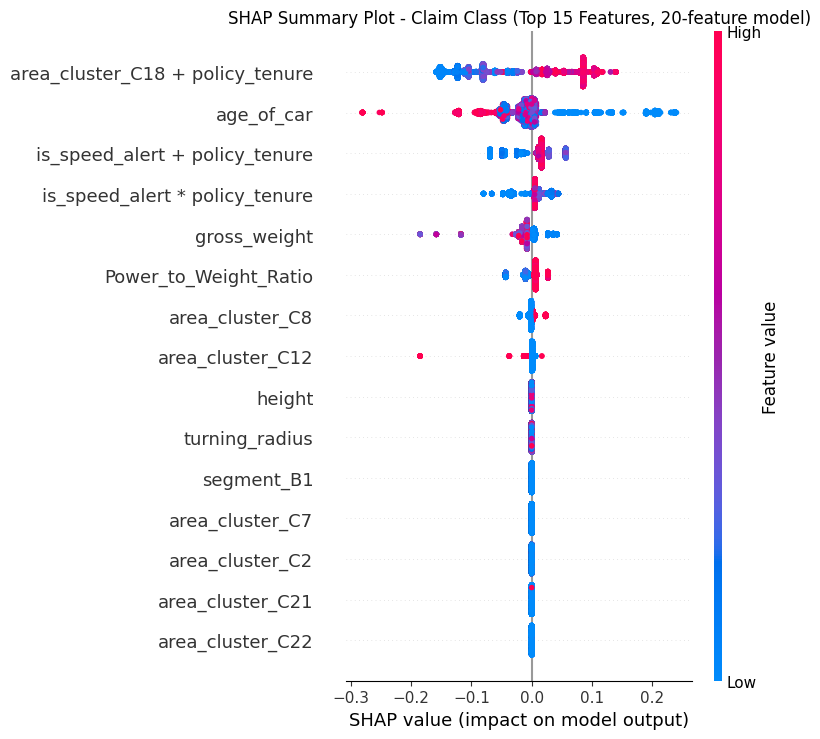

,feature,mean_abs_shap,mean_signed_shap,value_shap_corr,direction,rank
0,area_cluster_C18 + policy_tenure,0.08443,-0.02512,0.89912,Increases claim risk,1
1,age_of_car,0.03519,-0.00493,-0.48853,Decreases claim risk,2
2,is_speed_alert + policy_tenure,0.02922,0.00191,0.55997,Increases claim risk,3
3,is_speed_alert * policy_tenure,0.01571,0.00366,0.22881,Increases claim risk,4
4,gross_weight,0.01336,-0.00815,-0.34902,Decreases claim risk,5
5,Power_to_Weight_Ratio,0.01262,-0.00048,0.70412,Increases claim risk,6
6,area_cluster_C8,0.00250,-0.00065,0.48024,Increases claim risk,7
7,area_cluster_C12,0.00129,-0.00014,-0.46842,Decreases claim risk,8
8,area_cluster_C3,0.00000,0.00000,0.00000,Neutral (not used by model),9
9,area_cluster_C7,0.00000,0.00000,0.00000,Neutral (not used by model),10


Retained Featuretools features: ['area_cluster_C18 + policy_tenure', 'is_speed_alert * policy_tenure', 'is_speed_alert + policy_tenure', 'age_of_policyholder + policy_tenure']
In top-10 SHAP: ['area_cluster_C18 + policy_tenure', 'is_speed_alert + policy_tenure', 'is_speed_alert * policy_tenure']


In [42]:
chosen_pre20 = chosen_model.named_steps["prep"]
final_est20  = chosen_model.named_steps["tree"]
feature_names20 = list(chosen_pre20.get_feature_names_out())

X_test_shap20 = pd.DataFrame(
    np.asarray(chosen_pre20.transform(X_test20)),
    columns=feature_names20, index=X_test20.index
)

explainer20 = shap.TreeExplainer(final_est20)
raw20 = explainer20.shap_values(X_test_shap20)

# handle both legacy list output and new 3D output (positive-class slice)
if isinstance(raw20, list):
    shap_pos20 = np.asarray(raw20[1])
elif np.ndim(raw20) == 3:
    shap_pos20 = raw20[:, :, 1]
else:
    shap_pos20 = np.asarray(raw20)

base20 = float(np.asarray(explainer20.expected_value).ravel()[-1])
recon = base20 + shap_pos20.sum(axis=1)
assert np.allclose(recon, final_est20.predict_proba(X_test_shap20)[:, 1], atol=1e-3), \
    "SHAP values do not add up to model output"
print("SHAP shape:", shap_pos20.shape, "| base value:", round(base20, 4))

# Summary plot
plt.figure()
shap.summary_plot(shap_pos20, X_test_shap20, feature_names=feature_names20,
                  max_display=15, show=False)
plt.title("SHAP Summary Plot - Claim Class (Top 15 Features, 20-feature model)")
plt.tight_layout()
plt.savefig(OUT_DIR / "shap_summary_plot_automl_top20.png", dpi=300, bbox_inches="tight")
plt.show(); plt.close()

# Feature summary: direction from correlation of feature value with its SHAP value
Xv = X_test_shap20.reset_index(drop=True)
sd = pd.DataFrame(shap_pos20, columns=feature_names20)

def vcorr(c):
    if Xv[c].nunique() < 2 or sd[c].nunique() < 2:
        return 0.0
    return float(np.corrcoef(Xv[c], sd[c])[0, 1])

feature_summary20 = pd.DataFrame({
    "feature": feature_names20,
    "mean_abs_shap": np.abs(shap_pos20).mean(axis=0),
    "mean_signed_shap": shap_pos20.mean(axis=0),
    "value_shap_corr": [vcorr(c) for c in feature_names20],
})
feature_summary20["direction"] = np.where(
    feature_summary20["mean_abs_shap"] < 1e-6, "Neutral (not used by model)",
    np.where(feature_summary20["value_shap_corr"] > 0,
             "Increases claim risk", "Decreases claim risk"))
feature_summary20 = (feature_summary20.sort_values("mean_abs_shap", ascending=False)
                     .reset_index(drop=True))
feature_summary20["rank"] = feature_summary20.index + 1
feature_summary20.to_csv(OUT_DIR / "shap_feature_summary_automl_top20.csv", index=False)
display(feature_summary20.head(15).round(5))

# Are any retained Featuretools features in the top-10 SHAP features?
top10 = feature_summary20.head(10)
ft_top10 = top10[top10["feature"].isin(retained)]
print("Retained Featuretools features:", retained)
print("In top-10 SHAP:", ft_top10["feature"].tolist() if not ft_top10.empty else "none")

- `area_cluster_C18 + policy_tenure` was the most influential feature, with a mean absolute SHAP value of **0.08443**.
- `age_of_car` ranked second, followed by `is_speed_alert + policy_tenure` and `is_speed_alert * policy_tenure`.
- Higher values of the engineered interaction features were positively correlated with SHAP contributions, indicating an association with increased predicted claim risk.
- `age_of_car` and `gross_weight` showed negative value–SHAP correlations, indicating an association between higher values and lower predicted claim risk.
- Several area-cluster features had zero SHAP importance, indicating no contribution to predictions in this model; SHAP describes model associations, not causation.

In [55]:
#loading the raw dataset to extract the policy id
df_raw = pd.read_csv(r"dataset.csv")

In [44]:
# Compare the row counts and order of the original dataset with the cleaned dataset
assert len(df_raw) == len(df), "Row counts differ - cleaning removed rows"
assert (df_raw["is_claim"].values == df["is_claim"].values).all(), "Row order differs"

In [45]:
policy_id = df_raw.loc[X_test20.index, "policy_id"].values

In [46]:
import numpy as np
import pandas as pd

# Predictions from the new Top 20-feature model
claim_probability = best_tree20.predict_proba(X_test20)[:, 1]
predicted_class = best_tree20.predict(X_test20)

# Policy IDs aligned to the test-set rows
policy_id = df_raw.loc[X_test20.index, "policy_id"].values

labels = ["Low", "Medium", "High", "Very High"]

print("Number of features:", X_test20.shape[1])
print("Number of test predictions:", len(claim_probability))

Number of features: 20
Number of test predictions: 11719


In [47]:
prob_s = pd.Series(claim_probability)

pct_rank = (
    prob_s.sample(frac=1, random_state=42)
          .rank(method="first", pct=True)
          .sort_index()
)

risk_level = pd.cut(
    pct_rank,
    bins=[0, 0.40, 0.75, 0.90, 1.0],
    labels=labels,
    include_lowest=True
)

prediction_output_automl= pd.DataFrame({
    "policy_id": policy_id,
    "actual_outcome": np.asarray(y_test),
    "predicted_class": predicted_class,
    "claim_probability": claim_probability,
    "risk_level": risk_level
})

assert len(prediction_output_automl) == len(X_test20)

print(prediction_output_automl.head())

  policy_id  actual_outcome  predicted_class  claim_probability risk_level
0   ID38216               0                1           0.608516     Medium
1   ID03598               0                0           0.218289        Low
2   ID32005               0                0           0.352408        Low
3   ID20541               0                1           0.608516     Medium
4   ID55339               0                0           0.218289        Low


In [48]:
claim_rates = (
    prediction_output_automl
    .groupby("risk_level", observed=False)["actual_outcome"]
    .mean()
    .reindex(labels)
)

print("Actual claim rate by risk band (%):")
print((claim_rates * 100).round(2))

is_monotonic = bool(
    claim_rates.notna().all()
    and (claim_rates.diff().dropna() > 0).all()
)

print("\nMonotonic increase confirmed:", is_monotonic)

if is_monotonic:
    print("Claim rates increase strictly from Low to Very High.")
else:
    print("WARNING: Claim rates do not increase strictly across all bands.")

Actual claim rate by risk band (%):
risk_level
Low           3.31
Medium        7.68
High          8.87
Very High    10.58
Name: actual_outcome, dtype: float64

Monotonic increase confirmed: True
Claim rates increase strictly from Low to Very High.


In [49]:
print("Risk-band distribution (%):")
print(
    (prediction_output_automl["risk_level"]
     .value_counts(normalize=True)
     .reindex(labels) * 100).round(2)
)

prediction_output_automl.to_csv("prediction_output_automl.csv", index=False)

print("\nSaved: prediction_output_automl.csv")
print("Columns:", prediction_output_automl.columns.tolist())
print("Shape:", prediction_output_automl.shape)

Risk-band distribution (%):
risk_level
Low          39.99
Medium       35.00
High         15.00
Very High    10.00
Name: proportion, dtype: float64

Saved: prediction_output_automl.csv
Columns: ['policy_id', 'actual_outcome', 'predicted_class', 'claim_probability', 'risk_level']
Shape: (11719, 5)


##### Compare the risk-band distributions with Notebook 2

In [50]:
labels = ["Low", "Medium", "High", "Very High"]

automl_dist = (
    prediction_output_automl["risk_level"]
    .value_counts(normalize=True)
    .reindex(labels, fill_value=0)
    .mul(100)
)

notebook2_output = pd.read_csv("prediction_output.csv")

notebook2_dist = (
    notebook2_output["risk_level"]
    .value_counts(normalize=True)
    .reindex(labels, fill_value=0)
    .mul(100)
)

distribution_comparison = pd.DataFrame({
    "Notebook 2 (%)": notebook2_dist,
    "AutoML (%)": automl_dist
})

distribution_comparison["Difference (percentage points)"] = (
    distribution_comparison["AutoML (%)"]
    - distribution_comparison["Notebook 2 (%)"]
)

print(distribution_comparison.round(2))

            Notebook 2 (%)  AutoML (%)  Difference (percentage points)
risk_level                                                            
Low                  39.99       39.99                             0.0
Medium               35.00       35.00                             0.0
High                 15.00       15.00                             0.0
Very High            10.00       10.00                             0.0


- The risk-level distributions were identical for Notebook 2 and AutoML.
- **Low risk:** 39.99%; **Medium risk:** 35.00%.
- **High risk:** 15.00%; **Very High risk:** 10.00%.
- The difference between the two approaches was **0 percentage points** across all four risk categories.
- This indicates consistent risk-band proportions, but does not by itself establish that both models have identical predictions or predictive performance.

##### Calculate the five KPIs

In [51]:
# Merge risk levels onto the full raw dataset
df_kpi = df_raw.merge(
    prediction_output_automl[["policy_id", "risk_level"]],
    on="policy_id",
    how="left",
    validate="one_to_one"
)

# Calculate the five KPIs
total_policies = df_kpi["policy_id"].nunique()

total_claims = df_kpi["is_claim"].sum()

claim_rate_pct = (
    df_kpi["is_claim"].mean() * 100
)

high_risk_customers = df_kpi["risk_level"].isin(
    ["High", "Very High"]
).sum()

average_ncap_rating = df_kpi["ncap_rating"].mean()

kpi_results = pd.DataFrame({
    "KPI": [
        "Total policies",
        "Total claims",
        "Claim rate (%)",
        "High-risk customers (High + Very High)",
        "Average NCAP rating"
    ],
    "Value": [
        total_policies,
        total_claims,
        round(claim_rate_pct, 2),
        high_risk_customers,
        round(average_ncap_rating, 2)
    ]
})

print(kpi_results)

                                      KPI     Value
0                          Total policies  58592.00
1                            Total claims   3748.00
2                          Claim rate (%)      6.40
3  High-risk customers (High + Very High)   2930.00
4                     Average NCAP rating      1.76


##### Merging prediction_output and raw dataset

In [52]:
df_final = df_raw.merge(
    prediction_output_automl[
        ["policy_id", "predicted_class",
         "claim_probability", "risk_level"]
    ],
    on="policy_id",
    how="left",
    validate="one_to_one"
)

In [53]:
df_final.shape

(58592, 47)

In [54]:
df_final.to_csv("final_predicted_data.csv", index=False)

print("Final predicted dataset saved successfully!")

Final predicted dataset saved successfully!
